# Week 6: A tool around your model

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. It needs a GPU runtime (Runtime → Change runtime type → A100), and the Hugging Face token from the slider notebook in Colab's Secrets panel with the name HF_TOKEN. The output below was made on a laptop with the museum chairs model from the week 5 slides.

## 1. Setup

It installs the versions of the libraries we tested with, then checks the GPU and your Hugging Face token, the same as in the slider notebook.

In [1]:
import os, sys, gc, re
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install diffusers==0.43.0 transformers==5.23.0 accelerate==1.15.0 peft==0.21.3 sentencepiece gradio==6.32.0
import requests, torch
from huggingface_hub import auth_check
if IN_COLAB:
    assert torch.cuda.is_available(), "This notebook needs a GPU: Runtime → Change runtime type → A100."
    from google.colab import userdata
    try:
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        raise RuntimeError("Add your Hugging Face token in Colab's Secrets panel (the key icon on the left) "
                           "with the name HF_TOKEN, and turn on Notebook access.") from None
try:
    auth_check("black-forest-labs/FLUX.1-dev")
except Exception:
    raise RuntimeError("Hugging Face did not let this token open FLUX.1 [dev]. Check the token, and accept the license "
                       "at huggingface.co/black-forest-labs/FLUX.1-dev with the same account.") from None
print("ready")

ready


## 2. Your model

LORA_URL starts as the museum chairs model. Replace it with your link from lora-links.txt, and change TRIGGER, SUBJECT and PROMPT to describe your own images. PLUS and MINUS are the two ends of your slider from week 5. The tool's code reads these settings when it starts.

In [2]:
LORA_URL = "https://replicate.delivery/xezq/KdQIrXFTvNZ0BdOrYZ1i1ovkskK4qiFV8ORnLlIpfX3RMuwLA/flux-lora.tar"  # the week 5 example; paste your own link from lora-links.txt
TRIGGER = "MUSCHR"
SUBJECT = "chair"
PROMPT = f"a photo of a {TRIGGER} {SUBJECT}, museum object photograph on a plain grey backdrop"
PLUS = "ornate chair with carved decoration and tufted upholstery"
MINUS = "simple chair with straight lines and no decoration"

# app.py reads these when it starts.
os.environ.update(LORA_URL=LORA_URL, TRIGGER=TRIGGER, SUBJECT=SUBJECT, PROMPT=PROMPT, PLUS=PLUS, MINUS=MINUS)
print("settings ready")

settings ready


## 3. The tool's code

With USE_EXAMPLE = True, it downloads app.py, a small Gradio page that makes images with your model and its slider, and CLAUDE.md, the instruction file from the week 6 slides. You can download both from the Files panel on the left and give them to your coding agent. To try a version that your agent changed, set USE_EXAMPLE to False, run this cell, and upload that app.py. The cell prints the tool's buttons, so you can check that the change is there.

In [3]:
USE_EXAMPLE = True  # True: the example tool. False: upload an app.py that your coding agent changed.
EXAMPLE = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/chair-tool/"

if USE_EXAMPLE:
    for name in ("app.py", "CLAUDE.md"):
        open(name, "w").write(requests.get(EXAMPLE + name, timeout=60).text)
else:
    from google.colab import files
    up = files.upload()
    assert "app.py" in up, "Upload a file called app.py."
    open("app.py", "wb").write(up["app.py"])
code = open("app.py").read()
print("app.py:", len(code.splitlines()), "lines, buttons:", ", ".join(re.findall(r'gr\.Button\("([^"]+)"', code)))

app.py: 96 lines, buttons: Make image


## 4. Load the tool

It runs app.py, which downloads your LoRA and loads FLUX.1 [dev], so it can take several minutes the first time. If you run it again for another app.py, it first frees the GPU memory that the version you loaded before was using.

In [4]:
if "tool" in globals():  # free the version you loaded before, so two image models don't fill the GPU
    try:
        tool["demo"].close()
    except Exception:
        pass
    tool.clear(); gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else torch.mps.empty_cache()
tool = {"__name__": "app"}  # runs app.py here without opening the page yet
exec(compile(code, "app.py", "exec"), tool)
print("tool ready")

LoRA: lora/8041a651/flux-lora/flux-lora.safetensors


tool ready


## 5. Try it once

It makes one image with the slider at 1.5. Before you open the tool, check that the image looks like your training images and that it shows more of your PLUS phrase.

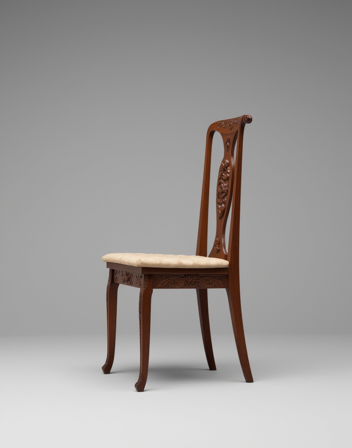

In [5]:
first = tool["make_image"](PLUS, MINUS, 1.5)
first.save("first.png")
first.resize((first.width // 2, first.height // 2))

## 6. Open the tool

The tool opens below the cell. Gradio also prints a public link to it, and anyone with that link can use your GPU while the tool runs, so share it only with your team.

In [6]:
if IN_COLAB:
    tool["demo"].launch()
else:
    print("In Colab, the tool opens below this cell.")

In Colab, the tool opens below this cell.


## 7. Change the tool with a coding agent

The example tool has one button, Make image. Write an instruction file for your own tool, then ask your coding agent for the same change twice: once in a folder with app.py and your instruction file, and once with app.py alone. For example, you can ask for the Make strip button from the week 6 slides. Upload each version in section 3 and try it with sections 4 to 6. As on the slides, write down the steps, the time and what broke each time, and which version you kept. For the hand-in, make a one-minute screen recording of your tool, and add your instruction file and a few sentences comparing the two runs.